In [19]:
from imports import *

In [20]:

def MMGKS2(A, b, L, pnorm=2, qnorm=1, projection_dim=3, n_iter=5, regparam='gcv', x_true=None, non_neg= True, power = 1, **kwargs):

    dp_stop = kwargs['dp_stop'] if ('dp_stop' in kwargs) else False

    epsilon = kwargs['epsilon'] if ('epsilon' in kwargs) else 0.1
    (U, B, V) = golub_kahan_2(A, b, projection_dim, dp_stop, **kwargs)
    
    x_history = []
    lambda_history = []
    residual_history = []
    e = 1
    x = A.T @ b 
    AV = A@V
    LV = L@V
    for ii in tqdm(range(n_iter), desc='running MMGKS...'):
        # y= la.pinv(V)@x
        v = A @ x - b
        wf = (v**2 + epsilon**2)**(pnorm/2 - 1)


        AA = AV*wf
        (Q_A, R_A) = la.qr(AA, mode='economic') 
        # g= np.linalg.lstsq(R_A,Q_A.T@b)[0]
        u =(L @ x) #*(1/la.norm(L@(V@g),1)) 
        
        wr = smoothed_holder_weights(u, epsilon=epsilon, p=qnorm).reshape((-1,1))
        LL = LV * (wr**power)
        (Q_L, R_L) = la.qr(LL, mode='economic') 
        if regparam == 'gcv':
            lambdah = generalized_crossvalidation_2(Q_A, R_A, R_L, wf *b, **kwargs)
        elif regparam == 'dp':
            lambdah = discrepancy_principle(Q_A, R_A, R_L, wf *b, **kwargs)
        else:
            lambdah = regparam
        
        lambda_history.append(lambdah)
        y,_,_,_ = np.linalg.lstsq(np.concatenate((R_A, np.sqrt(lambdah) * R_L)), 
                        np.concatenate((Q_A.T@ b, np.zeros((R_L.shape[0],1)))),rcond=None)
        x = V @ y
        if (non_neg):
            x[x<0] = 0
        x_history.append(x)
        if ii >= R_L.shape[0]:
            break
        v = AV@y
        v = v - b
        u = LV @ y
        ra = wf * (AV @ y - b)
        ra = A.T @ ra
        rb = wr * (LV @ y)
        rb = L.T @ rb
        r = ra + lambdah * rb
        r = r - V @ (V.T @ r)
        r = r - V @ (V.T @ r)
        normed_r = r / la.norm(r) 
        vn = r / np.linalg.norm(r)
        V = np.column_stack((V, vn))
        Avn = A @ vn
        AV = np.column_stack((AV, Avn))
        Lvn = vn
        Lvn = L*vn
        LV = np.column_stack((LV, Lvn))
        residual_history.append(la.norm(r))
    if x_true is not None:
        x_true_norm = la.norm(x_true)
        rre_history = [la.norm(x - x_true)/x_true_norm for x in x_history]
        info = {'xHistory': x_history, 'regParam': lambdah, 'regParam_history': lambda_history, 'relError': rre_history, 'Residual': residual_history, 'its': ii}
    else:
        info = {'xHistory': x_history, 'regParam': lambdah, 'regParam_history': lambda_history, 'Residual': residual_history, 'its': ii}
    
    return (x, info)




In [21]:
import numpy as np
from imports import *

Tomo = Tomography()

In [22]:
#Specify the shape of the images, the number of images in the sequence and load the image sequence using the gen_seq_function
nx= 128

ny = nx
shape = (nx,ny)
size = nx*ny
t_end = 5

v_max = 2
v_min = 1
padding = 2
data = gen_im_seq(shape,t_end,v_max=v_max,v_min=v_min, padding =padding)
u_traj = data.u_traj
u_inv_traj = data.u_inv_traj
v_primes=data.v_primes
vs=data.vs

# A list of the locations of all pixels
R = np.array(list(np.ndindex(*shape)))
# u_traj = [u*10 for u in u_traj]

plt.set_cmap('inferno')
# u_traj_ = np.load('mnist_test_seq.npy')[:,0,:,:][0:t_end]#*10
# u_traj = [vec(u) for u in u_traj_]
# u_inv_traj=u_traj[::-1]

# v_max = 3

<Figure size 640x480 with 0 Axes>

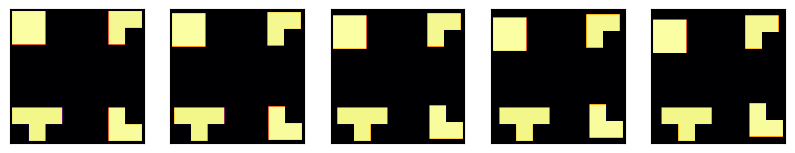

In [23]:
fig,ax=plt.subplots(1,t_end,figsize=(10,5))
for i in range(0,t_end):
    ax[i].imshow(u_traj[i].reshape(shape))
    ax[i].set_xticks([])
    ax[i].set_yticks([])

## Case: A; Views:5; NL:1%

In [24]:
#Generate the sinogram and the operator
views = 5
noise_level = 1e-2
x_traj = u_traj


X_true, A_bar,data_vec_bar,data_vec_true_bar,b_shape,L_bar, I_bar,deltas = gen_joint_tomo_op_and_data(x_traj, t_end, nx,ny, views,
                                                                           noise_level, case='a')
b_size = b_shape[0]*b_shape[1]
delta = np.mean(deltas) #la.norm(data_vec_true_bar-data_vec_bar)
print(delta)


[  0.  36.  72. 108. 144.]
[  7.2  43.2  79.2 115.2 151.2]
[ 14.4  50.4  86.4 122.4 158.4]
[ 21.6  57.6  93.6 129.6 165.6]
[ 28.8  64.8 100.8 136.8 172.8]
8.024783081054688


Text(0.5, 0.98, 'Noisy sinograms of the images in the sequence')

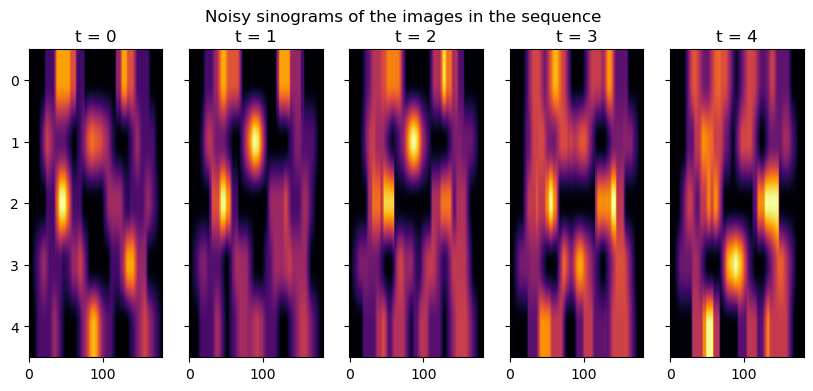

In [25]:
fig,ax=plt.subplots(1,t_end, sharey=True, figsize=(10,4))
data_vec_bar_list_c = [data_vec_bar[b_size*i:b_size*(i+1)] for i in range(t_end)]
data_vec_true_bar_list_c = [data_vec_true_bar[b_size*i:b_size*(i+1)] for i in range(t_end)]
for i in range(0,t_end):
    ax[i].imshow(data_vec_bar_list_c[i].reshape(b_shape),aspect='auto')
    ax[i].set_title(f't = {i}')
fig.suptitle('Noisy sinograms of the images in the sequence')

In [26]:

n_iter = 200
n_iter_b = 20
proj_dim = 10
vs_true = None# vs 
v_primes_true= None#v_primes 
reduction = True
scale = 2
epsilon=1e-1
non_neg = False



In [27]:
# MMGKS

from imports import *
from trips.solvers.MMGKS import *
mypower = 1

(X_mmgks, info_mmgks) = MMGKS2(A_bar, data_vec_bar, L_bar, pnorm=2, qnorm=1, projection_dim=proj_dim, 
                        n_iter =n_iter, regparam = 'dp', x_true = X_true.reshape((-1,1)), epsilon=epsilon,opt='nonscaled',delta=delta,non_neg=non_neg, power = 1)
error_mmgks = info_mmgks['relError'][-1]

X_mmgks[X_mmgks<0]=0
X_mmgks_list = [X_mmgks[size*i:size*(i+1)] for i in range(t_end)]

print('MMGKS Solution relative error:', error_mmgks)

running MMGKS...: 100%|██████████| 100/100 [00:32<00:00,  3.12it/s]

MMGKS Solution relative error: 0.4991872783838798


In [28]:
# MMGKS

from imports import *
from trips.solvers.MMGKS import *
mypower = 0.5

(X_mmgks, info_mmgks) = MMGKS2(A_bar, data_vec_bar, L_bar, pnorm=2, qnorm=1, projection_dim=proj_dim, 
                        n_iter =n_iter, regparam = 'dp', x_true = X_true.reshape((-1,1)), epsilon=epsilon,opt='nonscaled',delta=delta,non_neg=non_neg, power = mypower)
error_mmgks = info_mmgks['relError'][-1]

X_mmgks[X_mmgks<0]=0
X_mmgks_list = [X_mmgks[size*i:size*(i+1)] for i in range(t_end)]

print('MMGKS Solution relative error with power = 1:', error_mmgks)


running MMGKS...: 100%|██████████| 100/100 [00:30<00:00,  3.30it/s]

MMGKS Solution relative error with power = 1: 0.4862783874274165
